In [1]:
import sys
sys.path.append("../src")

import cv2
import numpy as np
import skimage
%pip install matplotlib
import matplotlib.pyplot as plt

from utils_cv import baca, tampil

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: C:\Users\mucha\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Scikit-image:", skimage.__version__)

OpenCV: 4.11.0
NumPy: 2.2.6
Scikit-image: 0.26.0


In [3]:
img = baca("../data/sintetis/citra/teh_041.png")

print("Shape:", img.shape)
print("Dtype:", img.dtype)
print("Nilai minimum:", img.min())
print("Nilai maksimum:", img.max())

Shape: (480, 640, 3)
Dtype: uint8
Nilai minimum: 17
Nilai maksimum: 236


In [4]:
print("Nilai piksel BGR pada koordinat (y=100, x=200):")
print(img[100, 200])

Nilai piksel BGR pada koordinat (y=100, x=200):
[191 197 203]


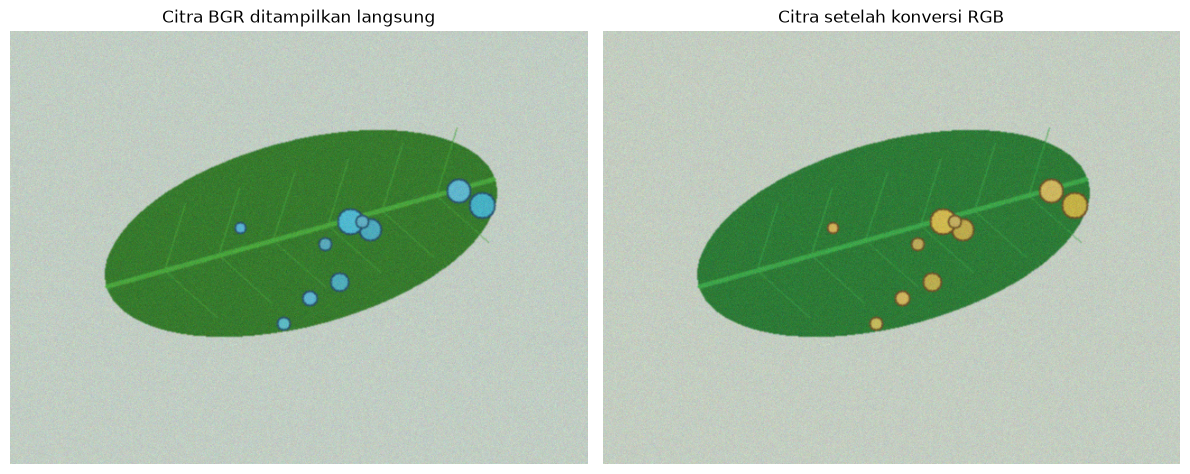

In [5]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Citra BGR ditampilkan langsung")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_rgb)
plt.title("Citra setelah konversi RGB")
plt.axis("off")

plt.tight_layout()
plt.savefig("../hasil/b1_bgr_rgb.png", dpi=150)
plt.show()

Problem Statement SIMUTEH</br></br>SIMUTEH (Sistem Identifikasi Mutu Teh) merupakan sistem berbasis computer vision yang dirancang untuk membantu petugas sortir dalam mengidentifikasi mutu daun teh berdasarkan kondisi visualnya.

Bagi petugas sortir dan kelompok tani yang menghadapi kesulitan dalam membedakan kualitas daun teh secara konsisten, kami membangun SIMUTEH sebagai sistem pengolahan citra yang menerima masukan berupa foto daun teh di atas nampan sortir menggunakan kamera telepon genggam. Sistem menghasilkan klasifikasi mutu daun ke dalam tiga kategori, yaitu Sehat, Bercak Ringan, dan Bercak Berat, disertai estimasi persentase luas bercak terhadap luas daun. Dengan demikian, SIMUTEH diharapkan dapat membantu proses penyortiran menjadi lebih terukur, konsisten, dan efisien, tanpa menggantikan keputusan akhir petugas sortir.

Sistem dirancang agar dapat menangani variasi kondisi pencahayaan seperti normal, gelap, terang, kontras rendah, dan bayangan sebagian. Sistem juga perlu memperhatikan privasi citra dan dapat dijalankan pada telepon genggam kelas menengah.

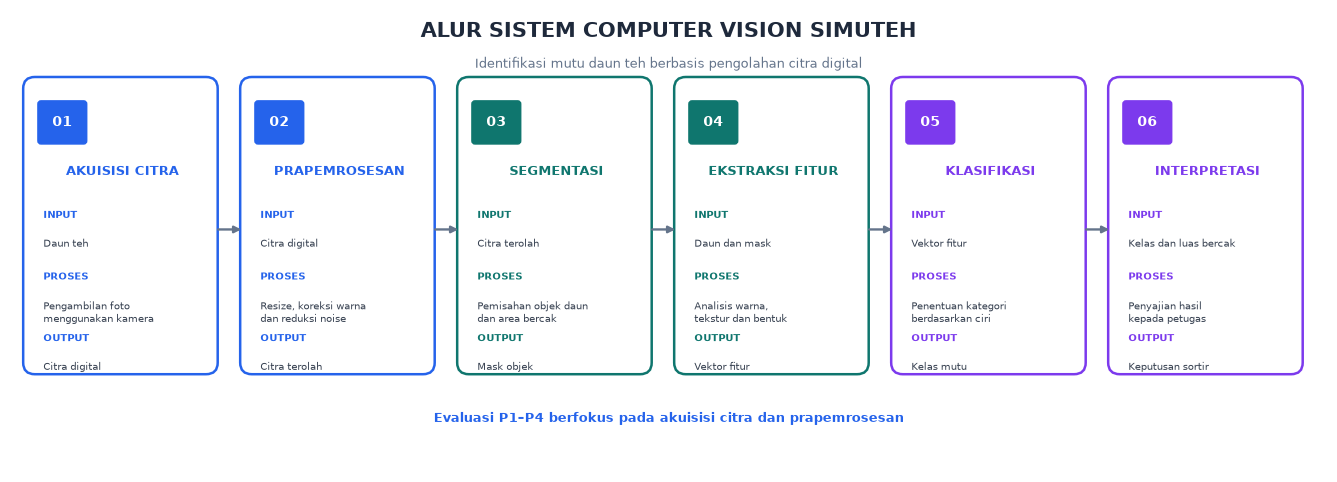

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

tahapan = [
    {
        "judul": "AKUISISI CITRA",
        "nomor": "01",
        "input": "Daun teh",
        "proses": "Pengambilan foto\nmenggunakan kamera",
        "output": "Citra digital"
    },
    {
        "judul": "PRAPEMROSESAN",
        "nomor": "02",
        "input": "Citra digital",
        "proses": "Resize, koreksi warna\ndan reduksi noise",
        "output": "Citra terolah"
    },
    {
        "judul": "SEGMENTASI",
        "nomor": "03",
        "input": "Citra terolah",
        "proses": "Pemisahan objek daun\ndan area bercak",
        "output": "Mask objek"
    },
    {
        "judul": "EKSTRAKSI FITUR",
        "nomor": "04",
        "input": "Daun dan mask",
        "proses": "Analisis warna,\ntekstur dan bentuk",
        "output": "Vektor fitur"
    },
    {
        "judul": "KLASIFIKASI",
        "nomor": "05",
        "input": "Vektor fitur",
        "proses": "Penentuan kategori\nberdasarkan ciri",
        "output": "Kelas mutu"
    },
    {
        "judul": "INTERPRETASI",
        "nomor": "06",
        "input": "Kelas dan luas bercak",
        "proses": "Penyajian hasil\nkepada petugas",
        "output": "Keputusan sortir"
    }
]

fig, ax = plt.subplots(figsize=(17, 6))
ax.set_xlim(0, 17)
ax.set_ylim(0, 6)
ax.axis("off")

warna_tahap = [
    "#2563eb", "#2563eb", "#0f766e",
    "#0f766e", "#7c3aed", "#7c3aed"
]

for i, data in enumerate(tahapan):
    x = 0.25 + i * 2.8
    y = 1.35
    w, h = 2.35, 3.7

    warna = warna_tahap[i]

    # Kartu utama
    kartu = patches.FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08,rounding_size=0.15",
        facecolor="#ffffff",
        edgecolor=warna,
        linewidth=1.8
    )
    ax.add_patch(kartu)

    # Bagian nomor
    ax.add_patch(patches.FancyBboxPatch(
        (x + 0.15, y + 2.95), 0.55, 0.48,
        boxstyle="round,pad=0.04",
        facecolor=warna,
        edgecolor=warna
    ))

    ax.text(
        x + 0.425, y + 3.19, data["nomor"],
        color="white", ha="center",
        va="center", fontsize=10, fontweight="bold"
    )

    ax.text(
        x + 1.2, y + 2.55, data["judul"],
        ha="center", va="center",
        fontsize=9, fontweight="bold",
        color=warna
    )

    # Informasi input, proses, output
    informasi = [
        ("INPUT", data["input"]),
        ("PROSES", data["proses"]),
        ("OUTPUT", data["output"])
    ]

    posisi = [1.95, 1.15, 0.35]

    for (label, isi), py in zip(informasi, posisi):
        ax.text(
            x + 0.18, y + py,
            label,
            fontsize=7, fontweight="bold",
            color=warna
        )
        ax.text(
            x + 0.18, y + py - 0.27,
            isi,
            fontsize=7.5, color="#374151",
            va="top"
        )

    # Penghubung
    if i < 5:
        ax.annotate(
            "",
            xy=(x + 2.77, y + 1.8),
            xytext=(x + 2.4, y + 1.8),
            arrowprops=dict(
                arrowstyle="-|>",
                color="#64748b",
                lw=1.7
            )
        )

ax.text(
    8.5, 5.65,
    "ALUR SISTEM COMPUTER VISION SIMUTEH",
    ha="center", fontsize=15,
    fontweight="bold", color="#1e293b"
)

ax.text(
    8.5, 5.25,
    "Identifikasi mutu daun teh berbasis pengolahan citra digital",
    ha="center", fontsize=9, color="#64748b"
)

ax.text(
    8.5, 0.65,
    "Evaluasi P1–P4 berfokus pada akuisisi citra dan prapemrosesan",
    ha="center", fontsize=9,
    color="#2563eb", fontweight="bold"
)

plt.savefig(
    "../hasil/b1_pipeline.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

### Tabel 6. Risiko Responsible Computer Vision SIMUTEH pada B1

| Aspek | Risiko pada SIMUTEH | Mitigasi Awal |
|---|---|---|
| **Privasi citra** | Foto daun yang diambil di lokasi sortir berpotensi memuat wajah petani, identitas pribadi, atau informasi lokasi kebun melalui metadata foto. | Menghindari pengambilan wajah dan identitas petani, menghapus metadata EXIF sebelum publikasi, serta meminta izin sebelum menggunakan atau membagikan foto. |
| **Bias dan keadilan** | Sistem berpotensi menghasilkan klasifikasi yang kurang akurat pada kondisi pencahayaan tertentu sehingga daun dari kondisi pemotretan berbeda memperoleh penilaian yang tidak konsisten. | Menggunakan data yang mewakili berbagai kondisi pencahayaan, seperti normal, gelap, terang, kontras rendah, dan bayangan. Melakukan pengujian pada setiap kondisi. |
| **Transparansi** | Petugas sortir mungkin tidak mengetahui alasan suatu daun dikategorikan sebagai Sehat, Bercak Ringan, atau Bercak Berat. | Menampilkan hasil klasifikasi disertai informasi pendukung, seperti persentase luas bercak, serta menjelaskan bahwa sistem merupakan alat bantu penyortiran. |
| **Keamanan data** | Dataset dan hasil pengolahan citra berpotensi diakses atau diubah oleh pihak yang tidak memiliki izin. | Membatasi akses terhadap data, menyimpan berkas pada lokasi yang terkontrol, dan membuat salinan cadangan secara berkala. |
| **Dampak sosial** | Kesalahan klasifikasi dapat menyebabkan kerugian bagi petani atau pihak pengolah teh, terutama jika hasil sistem digunakan sebagai satu-satunya dasar penentuan mutu. | Menempatkan SIMUTEH sebagai alat bantu pengambilan keputusan dan mempertahankan petugas sortir sebagai pihak yang menentukan keputusan akhir. |
| **Keterlacakan** | Hasil klasifikasi sulit dievaluasi kembali apabila citra masukan, parameter pengolahan, dan hasil pengujian tidak terdokumentasi. | Menyimpan citra masukan, hasil pengolahan, parameter yang digunakan, serta hasil klasifikasi agar proses dapat diperiksa dan diulang. |